#### Dataset

We use the Digits dataset provided by scikit-learn.

- 1,797 handwritten digit images
- Image size: 8 × 8 pixels
- 64 input features per image
- 10 target classes (digits 0–9)

<h1> MLP (Multilayer Perceptron) Digits Classification

#### Learning Objectives

- Load and explore a real classification dataset.
- Prepare and normalize input features.
- Implement a multiclass neural network from scratch.
- Implement Softmax and Cross-Entropy Loss.
- Train the network using Backpropagation and Gradient Descent.
- Evaluate classification performance and visualize errors.

In [20]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

<h3> Step 1: Loading and examining the dataset

In [5]:
# Load dataset
digits = load_digits()

X = digits.data.astype(np.float64)
y = digits.target.astype(np.int64)

# Inspect dataset
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("Number of samples:", len(X))
print("Number of features:", X.shape[1])
print("Number of classes:", len(np.unique(y)))

print("Pixel value range:", X.min(), "to", X.max())
print("Available classes:", np.unique(y))

print("\nFirst sample:")
print(X[0].reshape(8, 8))

print("First sample label:", y[0])

Feature matrix shape: (1797, 64)
Target vector shape: (1797,)
Number of samples: 1797
Number of features: 64
Number of classes: 10
Pixel value range: 0.0 to 16.0
Available classes: [0 1 2 3 4 5 6 7 8 9]

First sample:
[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]
First sample label: 0


#### Why are these dimensions important?

1. Network Input: Each image consists of 8 × 8 pixels. To feed it into the network, we convert it into a 64-element vector.

2. Input Layer: The network receives 64 pixel values; the pixel intensity values ​​range from 0 to 16. (64 Features)

3. Network Output: The network must predict one of ten classes (0 through 9); therefore, this is a multi-class problem—unlike the XOR problem, which involved only two classes. (10 Classes)

<h4> Display sample images

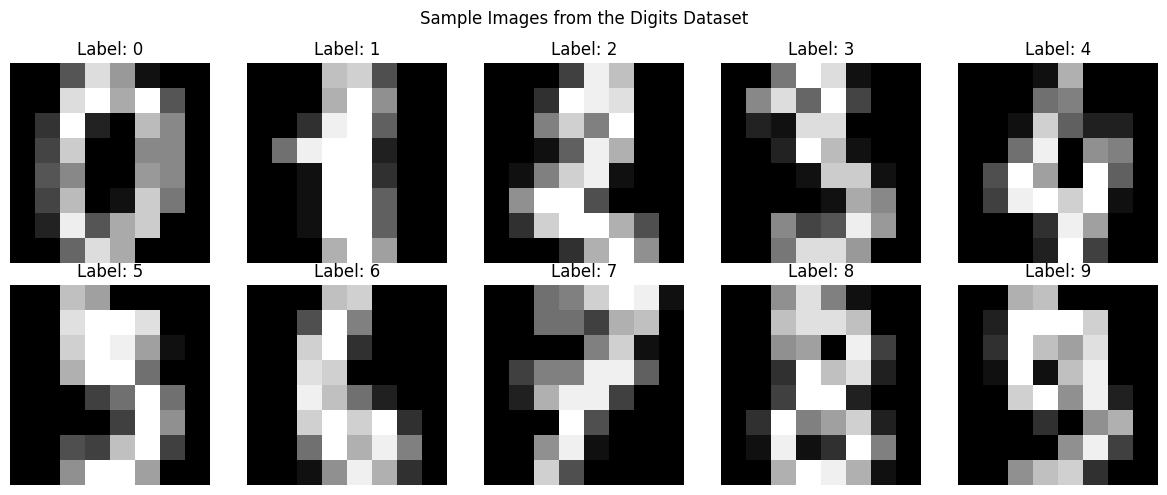

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(f"Label: {y[i]}")
    ax.axis("off")

plt.suptitle("Sample Images from the Digits Dataset")
plt.tight_layout()
plt.show()

<h3> Step 2: Train-Test Data Split

We use 80% of the data for training and 20% for evaluation. The `stratify=y` parameter helps ensure that the proportions of classes 0 through 9 are approximately maintained in both sets.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Training samples: 1437
Testing samples: 360
X_train shape: (1437, 64)
X_test shape: (360, 64)
y_train shape: (1437,)
y_test shape: (360,)


<h3> Step 3: Feature Normalization

The pixel values ​​are in the range of 0 to 16. By dividing them by 16, we scale all the features to the range of 0 to 1.

In [8]:
# Normalize pixel values to [0, 1]
X_train = X_train / 16.0
X_test = X_test / 16.0

print("Training pixel range:", X_train.min(), "to", X_train.max())
print("Testing pixel range:", X_test.min(), "to", X_test.max())

print("\nFirst normalized sample:")
print(X_train[0].reshape(8, 8))

Training pixel range: 0.0 to 1.0
Testing pixel range: 0.0 to 1.0

First normalized sample:
[[0.     0.     0.6875 0.625  0.75   0.875  0.6875 0.    ]
 [0.     0.     1.     1.     1.     1.     0.4375 0.    ]
 [0.     0.0625 1.     1.     1.     0.75   0.     0.    ]
 [0.     0.0625 0.3125 0.125  0.6875 0.9375 0.     0.    ]
 [0.     0.     0.0625 0.     0.125  1.     0.     0.    ]
 [0.     0.1875 0.75   0.     0.1875 0.9375 0.     0.    ]
 [0.     0.375  0.9375 0.5    0.8125 0.6875 0.     0.    ]
 [0.     0.     0.5625 0.875  0.5625 0.125  0.     0.    ]]


Why is normalization important? Input values ​​are brought to the same scale, which typically contributes to better stability and faster training of a neural network.

Data splitting is performed prior to training; therefore, information from the test set does not enter the learning process when the weights are being adjusted.

<h3> Step 4: Converting Labels to One-Hot Encoding

In the dataset, the label for each image is a number from 0 to 9. To calculate the gradient for the multi-class network, we convert the labels into 10-dimensional vectors.

In [9]:
num_classes = 10

y_train_onehot = np.eye(num_classes)[y_train]
y_test_onehot = np.eye(num_classes)[y_test]

print("One-hot training labels shape:", y_train_onehot.shape)
print("One-hot testing labels shape:", y_test_onehot.shape)

print("\nFirst training label:", y_train[0])
print("One-hot representation:", y_train_onehot[0])

print("\nSum of first one-hot vector:", y_train_onehot[0].sum())

One-hot training labels shape: (1437, 10)
One-hot testing labels shape: (360, 10)

First training label: 5
One-hot representation: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]

Sum of first one-hot vector: 1.0


<h3> Step 5: Defining Activation and Loss Functions

<h4> Multiclass Classification: Softmax and Cross-Entropy

In [10]:
# Activation functions
def relu(z):
    return np.maximum(0, z)


def softmax(logits):
    # Numerical stability: subtract the maximum logit
    shifted_logits = logits - np.max(
        logits, axis=1, keepdims=True
    )

    exp_values = np.exp(shifted_logits)

    return exp_values / np.sum(
        exp_values, axis=1, keepdims=True
    )


# Multiclass Cross-Entropy Loss
def cross_entropy_loss(y_true_onehot, probabilities):
    epsilon = 1e-12

    probabilities = np.clip(
        probabilities,
        epsilon,
        1.0
    )

    sample_losses = -np.sum(
        y_true_onehot * np.log(probabilities),
        axis=1
    )

    return np.mean(sample_losses)


print("ReLU test:", relu(np.array([-2.0, 0.0, 3.0])))

test_logits = np.array([[1.0, 2.0, 3.0]])
test_probabilities = softmax(test_logits)

print("Softmax probabilities:", test_probabilities)
print("Probability sum:", test_probabilities.sum())

ReLU test: [0. 0. 3.]
Softmax probabilities: [[0.09003057 0.24472847 0.66524096]]
Probability sum: 0.9999999999999999


Why Softmax? Unlike the XOR problem, which involved two classes, here we must choose between ten classes. Softmax calculates the probability for each class, and the sum of the probabilities for each sample equals one.

<h3> Step 6: Weight initialization and network execution

Now, we define the network parameters. To initialize the weights of the hidden layer, we use the He initialization method, ensuring that the initial scale of the weights is compatible with the ReLU activation function.

He Initialization Formula
Weights are typically sampled from a distribution with a mean of zero and the following variance:

$\boxed{\operatorname{Var}(W)=\frac{2}{n_{\text{in}}}}$

Where:
- $W$: Network weights
- $n_{\text{in}}$: Number of input neurons to the layer, or the number of inputs to each neuron (fan-in)
- $\operatorname{Var}(W)$: Variance of the weights

<h4> Network Creation

In [11]:
# Network architecture
input_size = 64
hidden_size = 64
output_size = 10

np.random.seed(42)

# He initialization for the ReLU hidden layer
W1 = np.random.randn(
    input_size, hidden_size
) * np.sqrt(2.0 / input_size)

b1 = np.zeros((1, hidden_size))

# Initialization for the output layer
W2 = np.random.randn(
    hidden_size, output_size
) * np.sqrt(1.0 / hidden_size)

b2 = np.zeros((1, output_size))


print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

W1 shape: (64, 64)
b1 shape: (1, 64)
W2 shape: (64, 10)
b2 shape: (1, 10)


<h4> Forward Propagation

In the Forward Propagation phase, each neuron first calculates the 
weighted sum:

$z=Wx+b$

Then, it applies the activation function:

$a=f(z)$

- $x$: Neuron input
- $W$: Weights
- $b$: Bias
- $f$: Activation function, such as ReLU
- $a$: Neuron output

In [12]:
def forward_propagation(X, W1, b1, W2, b2):
    # Hidden layer
    Z1 = X @ W1 + b1
    A1 = relu(Z1)

    # Output layer
    Z2 = A1 @ W2 + b2
    probabilities = softmax(Z2)

    return Z1, A1, Z2, probabilities


# Initial forward pass on training data
Z1, A1, Z2, train_probabilities = forward_propagation(
    X_train, W1, b1, W2, b2
)

initial_loss = cross_entropy_loss(
    y_train_onehot,
    train_probabilities
)

predictions = np.argmax(train_probabilities, axis=1)
initial_accuracy = np.mean(predictions == y_train)

print("Z1 shape:", Z1.shape)
print("A1 shape:", A1.shape)
print("Z2 shape:", Z2.shape)
print("Probabilities shape:", train_probabilities.shape)

print("\nFirst 5 probability sums:")
print(train_probabilities[:5].sum(axis=1))

print("\nFirst 10 predictions:")
print(predictions[:10])

print("First 10 true labels:")
print(y_train[:10])

print("\nInitial training loss:", initial_loss)
print("Initial training accuracy:", initial_accuracy)

Z1 shape: (1437, 64)
A1 shape: (1437, 64)
Z2 shape: (1437, 10)
Probabilities shape: (1437, 10)

First 5 probability sums:
[1. 1. 1. 1. 1.]

First 10 predictions:
[1 1 1 6 1 6 1 1 6 0]
First 10 true labels:
[5 0 5 7 1 2 9 9 2 0]

Initial training loss: 2.316417975785848
Initial training accuracy: 0.13291579679888657


#### Results:
- The shape of A1 is (1437, 64).
- The shape of train_probabilities is (1437, 10).
- The sum of the probabilities for each sample is approximately 1.0.
- Since the network has not yet been trained, the initial loss is close to 2.30—that is, approximately ln(10).
- The initial accuracy is typically low, as the weights have not yet learned from the data.

At this stage, no weights or biases are being updated.

<h4> Backpropagation

The goal of this stage is to calculate the gradients of all weights and biases using NumPy.

For the hidden layer, we use the derivative of ReLU; its derivative is 1 for positive inputs, and 0 for inputs that are zero or negative.

In [13]:
# Backpropagation for multiclass classification
N = X_train.shape[0]

# Forward propagation
Z1, A1, Z2, probabilities = forward_propagation(
    X_train, W1, b1, W2, b2
)

# Output layer gradients
dZ2 = (probabilities - y_train_onehot) / N

dW2 = A1.T @ dZ2
db2 = np.sum(dZ2, axis=0, keepdims=True)

# Hidden layer gradients
dA1 = dZ2 @ W2.T
dZ1 = dA1 * (Z1 > 0)

dW1 = X_train.T @ dZ1
db1 = np.sum(dZ1, axis=0, keepdims=True)

# Inspect gradient shapes
print("dW1 shape:", dW1.shape)
print("db1 shape:", db1.shape)
print("dW2 shape:", dW2.shape)
print("db2 shape:", db2.shape)

print("\nGradient magnitudes:")
print("Mean |dW1|:", np.mean(np.abs(dW1)))
print("Mean |db1|:", np.mean(np.abs(db1)))
print("Mean |dW2|:", np.mean(np.abs(dW2)))
print("Mean |db2|:", np.mean(np.abs(db2)))

dW1 shape: (64, 64)
db1 shape: (1, 64)
dW2 shape: (64, 10)
db2 shape: (1, 10)

Gradient magnitudes:
Mean |dW1|: 0.0033369346010013907
Mean |db1|: 0.006160503378410037
Mean |dW2|: 0.011733959292827136
Mean |db2|: 0.017403819102252048


<h4> Gradient Verification

In [14]:
# Numerical gradient check for W2[0, 0]

epsilon = 1e-5

def loss_with_W2(candidate_W2):
    _, _, _, probs = forward_propagation(
        X_train, W1, b1, candidate_W2, b2
    )
    return cross_entropy_loss(y_train_onehot, probs)


W2_plus = W2.copy()
W2_minus = W2.copy()

W2_plus[0, 0] += epsilon
W2_minus[0, 0] -= epsilon

numerical_gradient = (
    loss_with_W2(W2_plus) - loss_with_W2(W2_minus)
) / (2 * epsilon)

analytical_gradient = dW2[0, 0]

print("Analytical gradient:", analytical_gradient)
print("Numerical gradient:", numerical_gradient)

print(
    "Absolute difference:",
    abs(analytical_gradient - numerical_gradient)
)

Analytical gradient: 0.005824927836740589
Numerical gradient: 0.005824927828967929
Absolute difference: 7.772660119698127e-12


Testing a Single Step of Gradient Descent

In [15]:
# Save the current parameters
W1_new = W1 - 0.1 * dW1
b1_new = b1 - 0.1 * db1

W2_new = W2 - 0.1 * dW2
b2_new = b2 - 0.1 * db2

# Calculate loss before and after the update
_, _, _, probs_before = forward_propagation(
    X_train, W1, b1, W2, b2
)

_, _, _, probs_after = forward_propagation(
    X_train, W1_new, b1_new, W2_new, b2_new
)

loss_before = cross_entropy_loss(
    y_train_onehot, probs_before
)

loss_after = cross_entropy_loss(
    y_train_onehot, probs_after
)

print("Loss before update:", loss_before)
print("Loss after update:", loss_after)
print("Loss decreased:", loss_after < loss_before)

Loss before update: 2.316417975785848
Loss after update: 2.2834720702190623
Loss decreased: True


<h3> Step 7: Complete Neural Network Tutorial on Digits

At this stage, we use Full-Batch Gradient Descent; that is, in each epoch, we calculate the gradients using all 1,437 training samples and then update the weights.

In [16]:
# Full-batch training loop for the Digits dataset

np.random.seed(42)

input_size = 64
hidden_size = 64
output_size = 10

# Initialize parameters
W1 = np.random.randn(input_size, hidden_size) * np.sqrt(
    2.0 / input_size
)
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * np.sqrt(
    1.0 / hidden_size
)
b2 = np.zeros((1, output_size))

# Training configuration
learning_rate = 0.1
epochs = 1000
N = X_train.shape[0]

loss_history = []
accuracy_history = []

for epoch in range(epochs):

    # 1. Forward propagation
    Z1, A1, Z2, probabilities = forward_propagation(
        X_train, W1, b1, W2, b2
    )

    # 2. Calculate loss and training accuracy
    loss = cross_entropy_loss(
        y_train_onehot, probabilities
    )

    predictions = np.argmax(probabilities, axis=1)
    accuracy = np.mean(predictions == y_train)

    loss_history.append(loss)
    accuracy_history.append(accuracy)

    # 3. Backpropagation: output layer
    dZ2 = (probabilities - y_train_onehot) / N

    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # 4. Backpropagation: hidden layer
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0)

    dW1 = X_train.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    # 5. Gradient Descent update
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    # 6. Report progress
    if (epoch + 1) % 100 == 0:
        _, _, _, current_probabilities = forward_propagation(
            X_train, W1, b1, W2, b2
        )

        current_loss = cross_entropy_loss(
            y_train_onehot, current_probabilities
        )

        current_predictions = np.argmax(
            current_probabilities, axis=1
        )

        current_accuracy = np.mean(
            current_predictions == y_train
        )

        print(
            f"Epoch {epoch + 1:4d} | "
            f"Train Loss: {current_loss:.4f} | "
            f"Train Accuracy: {current_accuracy:.4f}"
        )


# Final training metrics
_, _, _, final_probabilities = forward_propagation(
    X_train, W1, b1, W2, b2
)

final_train_loss = cross_entropy_loss(
    y_train_onehot, final_probabilities
)

final_train_predictions = np.argmax(
    final_probabilities, axis=1
)

final_train_accuracy = np.mean(
    final_train_predictions == y_train
)

print("\nFinal Training Results")
print("----------------------")
print("Final train loss:", final_train_loss)
print("Final train accuracy:", final_train_accuracy)
print("Training epochs:", epochs)

Epoch  100 | Train Loss: 0.6230 | Train Accuracy: 0.9012
Epoch  200 | Train Loss: 0.3255 | Train Accuracy: 0.9381
Epoch  300 | Train Loss: 0.2292 | Train Accuracy: 0.9555
Epoch  400 | Train Loss: 0.1819 | Train Accuracy: 0.9617
Epoch  500 | Train Loss: 0.1534 | Train Accuracy: 0.9673
Epoch  600 | Train Loss: 0.1339 | Train Accuracy: 0.9722
Epoch  700 | Train Loss: 0.1193 | Train Accuracy: 0.9749
Epoch  800 | Train Loss: 0.1079 | Train Accuracy: 0.9777
Epoch  900 | Train Loss: 0.0985 | Train Accuracy: 0.9791
Epoch 1000 | Train Loss: 0.0907 | Train Accuracy: 0.9812

Final Training Results
----------------------
Final train loss: 0.09068616176466991
Final train accuracy: 0.9812108559498957
Training epochs: 1000


<h3> Step 8: Plotting learning curves

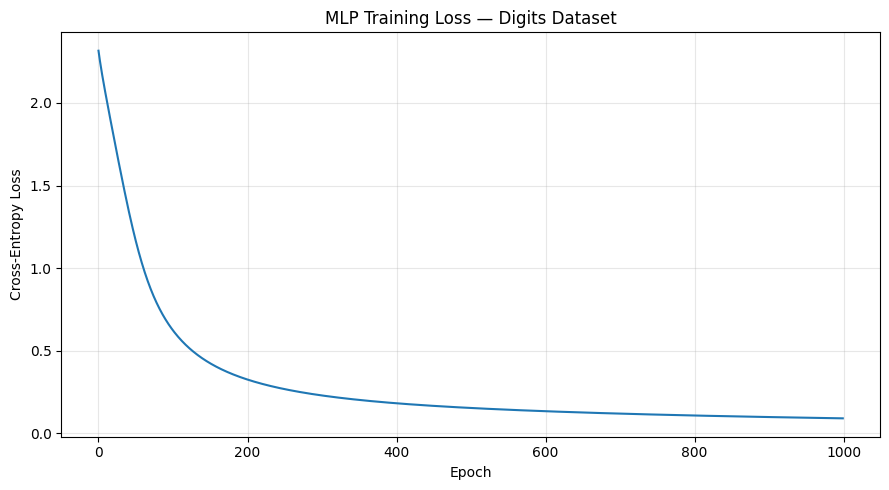

In [17]:
plt.figure(figsize=(9, 5))
plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("MLP Training Loss — Digits Dataset")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

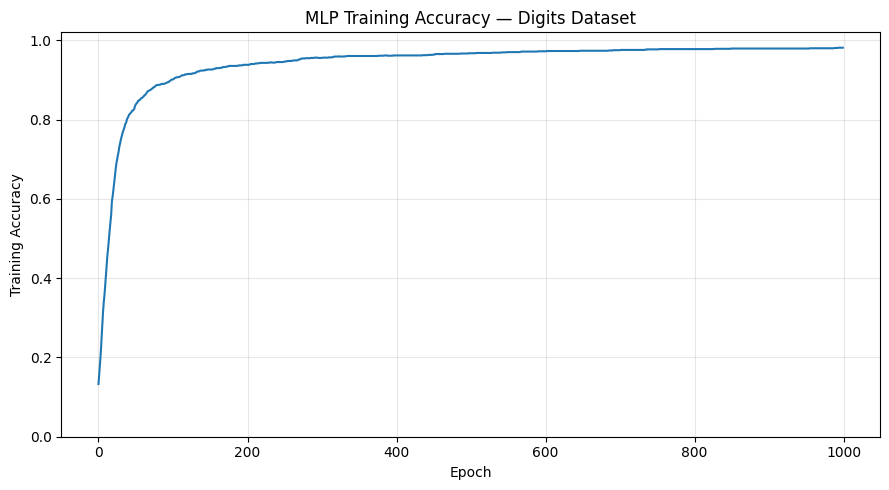

In [18]:
plt.figure(figsize=(9, 5))
plt.plot(accuracy_history)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.title("MLP Training Accuracy — Digits Dataset")
plt.ylim(0, 1.02)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<h3> Step 9: Evaluation on Test Data

In [19]:
# Evaluate the trained model on unseen test data

_, _, _, test_probabilities = forward_propagation(
    X_test, W1, b1, W2, b2
)

test_predictions = np.argmax(test_probabilities, axis=1)

test_loss = cross_entropy_loss(
    y_test_onehot, test_probabilities
)

test_accuracy = np.mean(test_predictions == y_test)

print("Test Results")
print("------------")
print("Test samples:", len(y_test))
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy (%): {test_accuracy * 100:.2f}%")

Test Results
------------
Test samples: 360
Test loss: 0.1277
Test accuracy: 0.9639
Test accuracy (%): 96.39%


The results are very good. The network, which we implemented entirely using NumPy, achieved an accuracy of 96.39% on data it had not seen during training. This indicates that the implementation was successful in practice and that the model was able to generalize to new data.

<h3> Step 10: Confusion Matrix and Error Analysis

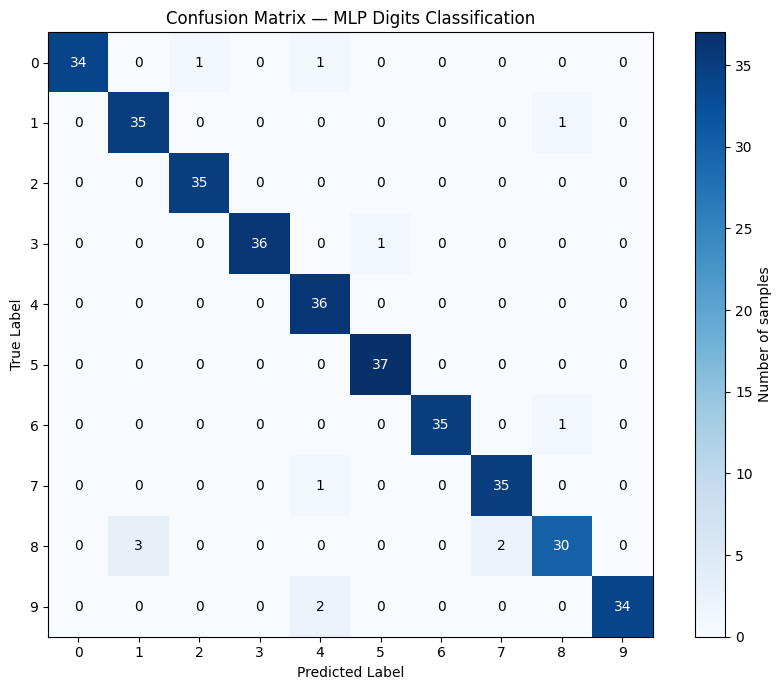

              precision    recall  f1-score   support

           0     1.0000    0.9444    0.9714        36
           1     0.9211    0.9722    0.9459        36
           2     0.9722    1.0000    0.9859        35
           3     1.0000    0.9730    0.9863        37
           4     0.9000    1.0000    0.9474        36
           5     0.9737    1.0000    0.9867        37
           6     1.0000    0.9722    0.9859        36
           7     0.9459    0.9722    0.9589        36
           8     0.9375    0.8571    0.8955        35
           9     1.0000    0.9444    0.9714        36

    accuracy                         0.9639       360
   macro avg     0.9650    0.9636    0.9635       360
weighted avg     0.9652    0.9639    0.9638       360



In [21]:
cm = confusion_matrix(y_test, test_predictions)

fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(cm, interpolation="nearest", cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of samples")

ax.set(
    xticks=np.arange(10),
    yticks=np.arange(10),
    xlabel="Predicted Label",
    ylabel="True Label",
    title="Confusion Matrix — MLP Digits Classification"
)

threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.tight_layout()
plt.show()

print(classification_report(y_test, test_predictions, digits=4))

In this chart, the values ​​on the main diagonal represent correct predictions; values ​​off the diagonal indicate model errors.

Three key points emerge from this table:
- The digit 8 is the weakest class; out of 35 actual instances, five were misclassified.
- The digits 2, 4, and 5 achieve 100% recall on this test set. This result applies specifically to these 360 ​​samples and does not guarantee perfect performance on new images.
- The precision for the digit 4 is 90%. Although all actual instances of the digit 4 were correctly identified, several instances of other digits were incorrectly predicted as 4.

Misclassified samples: 13


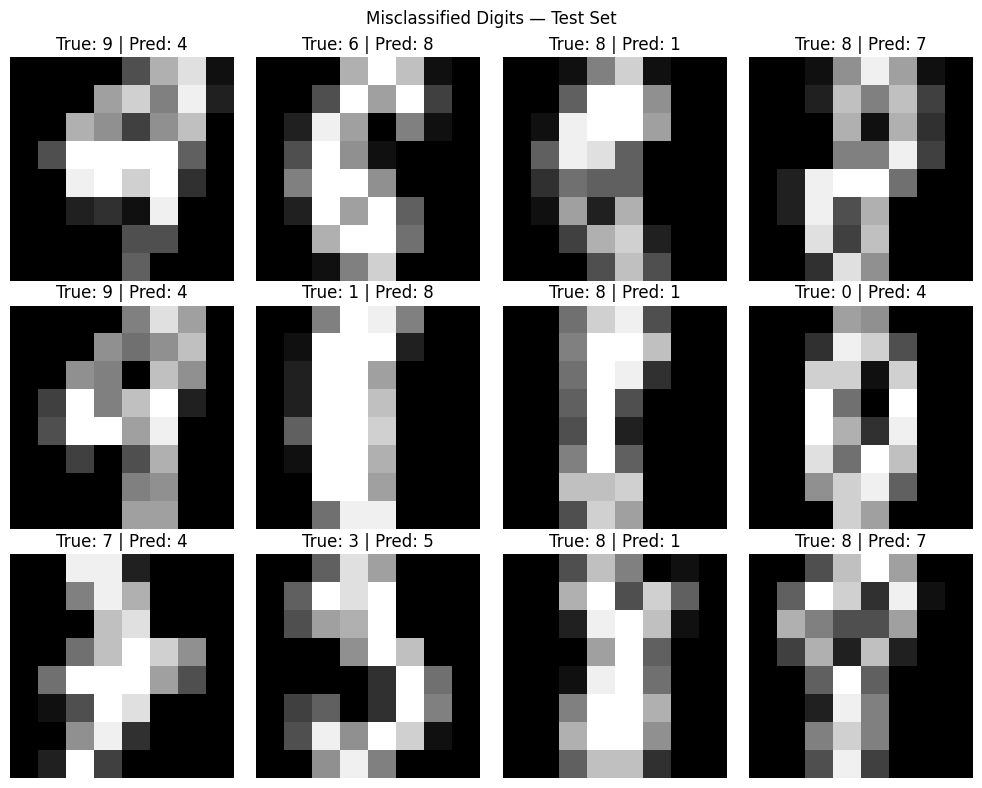

In [22]:
misclassified_indices = np.where(
    test_predictions != y_test
)[0]

print("Misclassified samples:", len(misclassified_indices))

n_show = min(12, len(misclassified_indices))

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
axes = axes.ravel()

for ax in axes:
    ax.axis("off")

for i, idx in enumerate(misclassified_indices[:n_show]):
    ax = axes[i]

    ax.imshow(
        X_test[idx].reshape(8, 8),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(
        f"True: {y_test[idx]} | Pred: {test_predictions[idx]}"
    )
    ax.axis("off")

plt.suptitle("Misclassified Digits — Test Set")
plt.tight_layout()
plt.show()

These images help us understand whether the misclassified digits resemble one another in terms of their visual appearance, or if the model has a specific weakness in recognizing certain patterns.

## Final Results and Conclusions

### Model Configuration
- Dataset: scikit-learn Digits
- Training samples: 1,437
- Test samples: 360
- Architecture: 64 → 64 → 10
- Hidden activation: ReLU
- Output activation: Softmax
- Loss function: Categorical Cross-Entropy
- Optimizer: Full-Batch Gradient Descent
- Learning rate: 0.1
- Training epochs: 1,000

### Final Performance
- Training loss: 0.0907
- Training accuracy: 98.12%
- Test loss: 0.1277
- Test accuracy: 96.39%
- Macro F1-score: 96.35%
- Correct test predictions: 347 / 360
- Incorrect test predictions: 13 / 360

### Key Findings
- The network learned useful representations from raw pixel features.
- Backpropagation was implemented and gradient-checked using NumPy.
- The model achieved strong test performance without using
  an automatic differentiation framework.
- Digit 8 was the most challenging class, with a recall of 85.71%.
- The training-test accuracy gap was approximately 1.73 percentage points.

### Limitations
- The dataset contains small 8 × 8 grayscale images.
- Only one hidden layer and one set of hyperparameters were tested.
- No separate validation set was used.
- Results may vary with initialization, architecture, and training settings.

### Conclusion
This project demonstrates the fundamentals of a neural network
classifier implemented from scratch, including forward propagation,
softmax, cross-entropy loss, backpropagation, gradient descent,
and evaluation on unseen data.